# Hälsostudie

Syftet med analysen är att undersöka hälsodata och analysera samband mellan olika variabler såsom ålder, vikt, blodtryck och sjukdom.



In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats


# Inläsning av Data


In [61]:
df = pd.read_csv("data/health_study_dataset.csv")

In [62]:
df.head()

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


In [63]:
df.columns

Index(['id', 'age', 'sex', 'height', 'weight', 'systolic_bp', 'cholesterol',
       'smoker', 'disease'],
      dtype='str')

In [64]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 56.4 KB


In [65]:
df.describe()


,id,age,height,weight,systolic_bp,cholesterol,disease
count,800.0000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000
mean,400.5000,49.426250,171.849250,73.413000,149.178625,4.929150,0.058750
std,231.0844,14.501118,9.804259,13.685059,12.793360,0.848413,0.235303
min,1.0000,18.000000,144.400000,33.700000,106.800000,2.500000,0.000000
25%,200.7500,39.000000,164.775000,64.800000,140.900000,4.327500,0.000000
50%,400.5000,50.000000,171.350000,73.200000,149.400000,4.970000,0.000000
75%,600.2500,59.000000,178.925000,82.600000,157.600000,5.482500,0.000000
max,800.0000,90.000000,200.400000,114.400000,185.900000,7.880000,1.000000


In [66]:
df.isnull().sum()

id             0
age            0
sex            0
height         0
weight         0
systolic_bp    0
cholesterol    0
smoker         0
disease        0
dtype: int64

# Utforskning av Dataset

In [67]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 56.4 KB


In [68]:
df.describe()

,id,age,height,weight,systolic_bp,cholesterol,disease
count,800.0000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000
mean,400.5000,49.426250,171.849250,73.413000,149.178625,4.929150,0.058750
std,231.0844,14.501118,9.804259,13.685059,12.793360,0.848413,0.235303
min,1.0000,18.000000,144.400000,33.700000,106.800000,2.500000,0.000000
25%,200.7500,39.000000,164.775000,64.800000,140.900000,4.327500,0.000000
50%,400.5000,50.000000,171.350000,73.200000,149.400000,4.970000,0.000000
75%,600.2500,59.000000,178.925000,82.600000,157.600000,5.482500,0.000000
max,800.0000,90.000000,200.400000,114.400000,185.900000,7.880000,1.000000


In [69]:
df.isnull().sum()

id             0
age            0
sex            0
height         0
weight         0
systolic_bp    0
cholesterol    0
smoker         0
disease        0
dtype: int64

# Beskrivande Analys

I denna del beräknas medelvärde, median, minvärde och maxvärde för de variabler som anges i datasetet

In [70]:
stats_table = df[
    ["age", "weight", "height", "systolic_bp", "cholesterol"]
     

].agg(
    ["mean", "median", "min", "max"]
    )

stats_table

,age,weight,height,systolic_bp,cholesterol
mean,49.42625,73.413,171.84925,149.178625,4.92915
median,50.00000,73.200,171.35000,149.400000,4.97000
min,18.00000,33.700,144.40000,106.800000,2.50000
max,90.00000,114.400,200.40000,185.900000,7.88000


# Visualiseringar

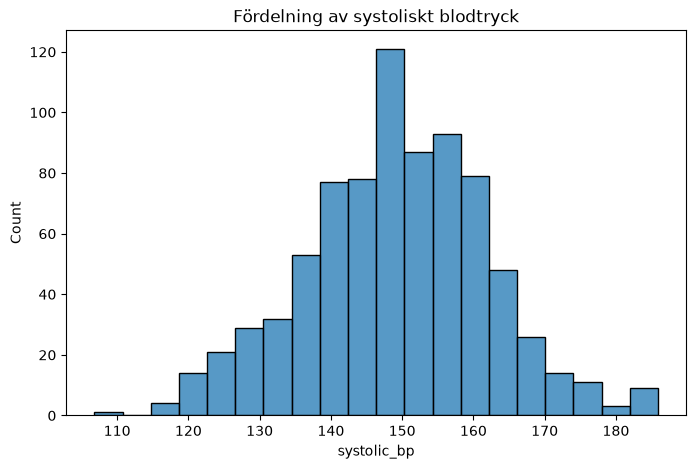

In [71]:
plt.figure(figsize=(8,5))

sns.histplot(
    df["systolic_bp"],
    bins=20
)

plt.title("Fördelning av systoliskt blodtryck")

plt.show()

Fördelning av systolistiskt blodtryck, histogram över alla representerade.

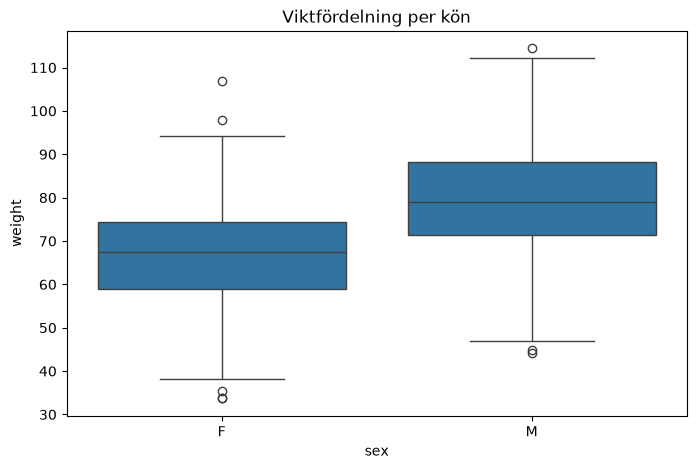

In [72]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="sex",
    y="weight"
)

plt.title("Viktfördelning per kön")

plt.show()

Viktfördelning per kön, boxplot som även visar avvikande värden.

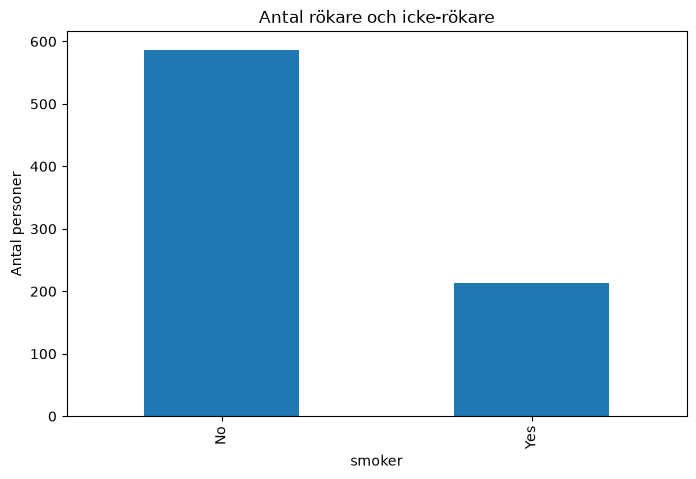

In [73]:
plt.figure(figsize=(8,5))

df["smoker"].value_counts().plot(kind="bar")

plt.title("Antal rökare och icke-rökare")

plt.ylabel("Antal personer")

plt.show()

Stapeldiagram över andelen rökare.

# Simulering

In [74]:
disease_rate = df["disease"].mean()

print("andel av personer med sjukdom:", disease_rate)

andel av personer med sjukdom: 0.05875


In [75]:
np.random.seed(42)

simulation = np.random.choice([0, 1],
                              size=1000,
                              p=[1-disease_rate, disease_rate]
                              )

print("verklig andel:",
      disease_rate,
      )
print("simulerad andel:",
      simulation.mean(),
      )

verklig andel: 0.05875
simulerad andel: 0.056


# Konfidensintervall

Här beräknas ett 95% konfidensintervall för medelvärdet av systoliskt blodtryck

In [76]:
mean_bp = df["systolic_bp"].mean()

std_bp = df["systolic_bp"].std()

n = len(df)

In [77]:
margin = 1.96 * (std_bp / np.sqrt(n))

In [78]:
lower = mean_bp - margin
upper = mean_bp + margin

print("95 % konfidensintervall:")
print(lower, upper)

95 % konfidensintervall:
148.29209036025347 150.06515963974655


# Bootstrap-Konfidensintervall

Jämförelse av metoder med Bootstrap

In [79]:
boot_means = []

In [80]:
for i in range(5000):
    sample = df["systolic_bp"].sample(
        n=len(df),
        replace=True)

    boot_means.append(sample.mean())

In [81]:
ci_boot = np.percentile(
    boot_means,
    [2.5, 97.5]
)

ci_boot

array([148.33585937, 150.08229375])

# Hypotesprövning
* Undersökning om rökare har högre blodtryck än icke-rökare.
* H0: Rökare och icke-rökare har samma genomsnittliga blodtryck
* H1: Rökare har högre genomsnittligt blodtryck än icke-rökare.

In [82]:
smokers = df[df["smoker"] == "Yes"]["systolic_bp"]

nonsmokers = df[df["smoker"] == "No"]["systolic_bp"]

In [83]:
print("antal rökare:", len(smokers))

print("antal icke-rökare:", len(nonsmokers))

antal rökare: 213
antal icke-rökare: 587


In [84]:
t_stat, p_value = stats.ttest_ind(
    smokers,
    nonsmokers,
    equal_var=False)

print("t-statistik:", t_stat)
print("p-värde:", p_value)

t-statistik: 0.4503433193393224
p-värde: 0.6527338743398997


In [85]:
if p_value < 0.05:
    print:("Det finns en statistiskt signifikant skillnad.")
else:
    print("Det finns ingen statistiskt signifikant skillnad.")

Det finns ingen statistiskt signifikant skillnad.


# Slutsats

Ett Welch's t-test användes för att jämföra det genomsnittliga systoliska blodtrycket mellan rökare och icke-rökare.

Testet gav ett p-värde på 0.653, vilket är större än signifikansnivån 0.05.

Resultatet visar därför att skillnaden mellan grupperna inte är statistiskt signifikant. Studien ger alltså inte stöd för hypotesen att rökare har högre systoliskt blodtryck än icke-rökare.

# Simmulering av testets styrka

In [86]:
power_results =[]

In [87]:
for i in range(1000):
    sample_smokers = smokers.sample(
        n=min(50, len(smokers)),
        replace=True)

    sample_nonsmokers = nonsmokers.sample(
        n=min(50, len(nonsmokers)),
        replace=True)

    p = stats.ttest_ind(
        sample_smokers,
        sample_nonsmokers,
        equal_var=False)

    power_results.append(p.pvalue < 0.05)

In [88]:
power = np.mean(power_results)

print("testets styrka:", power)

testets styrka: 0.051


# Tolkning

Simuleringen gav en uppskattad styrka på ca 0,051 (5,1%).

Detta innebär att i endast i 5,1% av simuleringarna upptäcktes en signifikativ skillnad. Resultatet kan förklaras av skillnaderna på grupperna är små, alternativt att datamängden inte är tillräkligt stor. 

# Metodval ( se över)

Beskrivande statistik användes för att sammanfatta datasetets viktigaste egenskaper.

Histogram, boxplot och stapeldiagram användes för att visualisera fördelningar och jämföra grupper.

Konfidensintervall beräknades med både normalapproximation och bootstrap för att jämföra två olika metoder för att uppskatta osäkerheten kring medelvärdet.

Welch's t-test användes vid hypotesprövningen eftersom grupperna kan ha olika varians och olika gruppstorlekar.

Simuleringar genomfördes med NumPy för att studera sjukdomsförekomst och för att undersöka hypotesprövningens styrka.

# Slutsats (se över)
Analysen visade att det genomsnittliga systoliska blodtrycket i datasetet var ungefär 149 mmHg.

Simuleringen av sjukdomsförekomst gav resultat som låg nära den verkliga andelen i datasetet, vilket tyder på att modellen fungerade som förväntat.

Vid hypotesprövningen hittades ingen statistiskt signifikant skillnad mellan rökare och icke-rökare (p = 0.653).

Power-simuleringen visade dessutom en låg teststyrka på cirka 5 %, vilket innebär att testet hade begränsad förmåga att upptäcka skillnader mellan grupperna.